<a href="https://colab.research.google.com/github/JohnGutierrez24/Analisis-de-sentimientos-en-resenas-de-ropa-utilizando-modelos-de-procesamiento-de-lenguaje-natural/blob/main/analisis_modelos_PLN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Análisis de sentimientos en reseñas de ropa utilizando modelos de procesamiento de lenguaje natural**
Estudiantes: John Alexander Gutiérrez Garay - Juan Felipe Murcia Rivera


#Descarga de Recursos y Carga del Dataset

In [ ]:
import seaborn as sns
import re
import string
from textblob import TextBlob
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, accuracy_score

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import nltk
nltk.download('vader_lexicon')

!pip install opendatasets
import opendatasets as od
import kagglehub
from kagglehub import KaggleDatasetAdapter
import os
import pandas as pd
import matplotlib.pyplot as plt

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


In [ ]:
dataset_link = "https://www.kaggle.com/datasets/jocelyndumlao/consumer-review-of-clothing-product"

In [ ]:
od.download(dataset_link)

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: juanmurcia01
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/jocelyndumlao/consumer-review-of-clothing-product


100%|██████████| 4.14M/4.14M [00:00<00:00, 673MB/s]

In [ ]:
os.chdir("/content/consumer-review-of-clothing-product")

In [ ]:
os.listdir('Consumer Review of Clothing Product')

['data_amazon.xlsx - Sheet1.csv']

In [ ]:
archivo = "Consumer Review of Clothing Product/data_amazon.xlsx - Sheet1.csv"
df = pd.read_csv(archivo)
df

,Title,Review,Cons_rating,Cloth_class,Materials,Construction,Color,Finishing,Durability
0,NaN,Absolutely wonderful - silky and sexy and comf...,4.0,Intimates,0.0,0.0,0.0,1.0,0.0
1,NaN,Love this dress! it's sooo pretty. i happene...,5.0,Dresses,0.0,1.0,0.0,0.0,0.0
2,Some major design flaws,I had such high hopes for this dress and reall...,3.0,Dresses,0.0,0.0,0.0,1.0,0.0
3,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5.0,Pants,0.0,0.0,0.0,0.0,0.0
4,Flattering shirt,This shirt is very flattering to all due to th...,5.0,Blouses,0.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...
49333,Dress felt and fit great. I got lots of compl...,Loved the color!!! Dress fit great and I got ...,5.0,Dresses,0.0,0.0,1.0,0.0,0.0
49334,Loved the dress but poor quality,This dress looked great and I loved the materi...,2.0,Dresses,1.0,0.0,0.0,0.0,1.0
49335,"Cute dress, didn't fit",Wanted this dress to work it didn't. It is ver...,1.0,Dresses,0.0,1.0,0.0,0.0,0.0
49336,Very cute!,No complaints othe than the zipper gets stuck ...,4.0,Dresses,0.0,0.0,0.0,0.0,1.0


In [ ]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [ ]:
pip install contractions

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 289.9/289.9 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.3/118.3 kB 12.2 MB/s eta 0:00:00


In [ ]:
pip install --upgrade contractions

#Analisis y Limpieza del Dataset

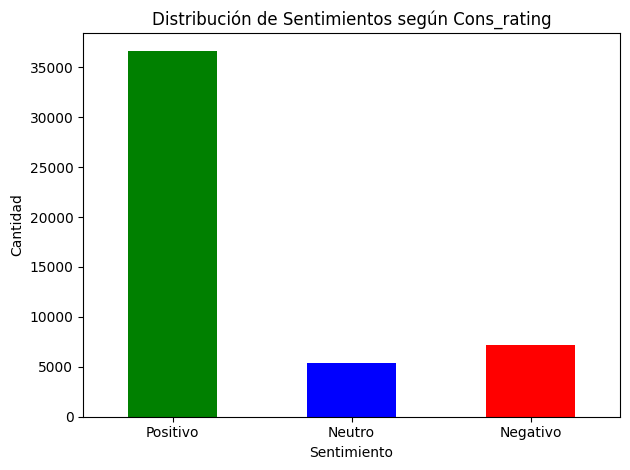

In [ ]:
# Mapear Cons_rating a categorías de sentimiento
def clasificar_sentimiento(rating):
    if rating in [1, 2]:
        return 'Negativo'
    elif rating == 3:
        return 'Neutro'
    elif rating in [4, 5]:
        return 'Positivo'
    else:
        return 'Desconocido'

df['Sentimiento'] = df['Cons_rating'].apply(clasificar_sentimiento)

# Contar frecuencia por categoría, en orden deseado
orden = ['Positivo', 'Neutro', 'Negativo']
conteo = df['Sentimiento'].value_counts().reindex(orden)

# Graficar
conteo.plot(kind='bar', color=['green', 'blue', 'red'])
plt.title('Distribución de Sentimientos según Cons_rating')
plt.xlabel('Sentimiento')
plt.ylabel('Cantidad')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:
import contractions

# Lista de stopwords en inglés
stop_words = set(stopwords.words('english'))

# Lista de palabras negativas a conservar
negations = {
    "out", "no", "not", "nor", "n't", "never", "none", "nothing", "nowhere", "neither",
    "cannot", "can't", "won't", "isn't", "aren't", "wasn't", "weren't", "don't",
    "doesn't", "didn't", "haven't", "hasn't", "hadn't", "wouldn't", "shouldn't",
    "mightn't", "mustn't"
}

# Se quitan las negaciones de la lista de stopwords
stop_words = stop_words - negations

# Función para limpiar el texto
def clean_text(text):
    if pd.isnull(text):
        return ""
    text = contractions.fix(text)  # Expande contracciones antes de limpiar
    text = text.lower()  # Minúsculas
    text = re.sub(r"http\S+|www\S+|https\S+", '', text)  # Eliminar URLs
    text = text.translate(str.maketrans('', '', string.punctuation))  # Eliminar puntuación
    text = re.sub(r'\d+', '', text)  # Eliminar números
    tokens = word_tokenize(text)  # Tokenizar
    tokens = [word for word in tokens if word not in stop_words]  # Eliminar stopwords (pero conservando negaciones)
    return ' '.join(tokens).strip()  # Unir tokens y eliminar espacios extra

# Aplicar la limpieza a la columna 'Review'
df['clean_text'] = df['Review'].apply(clean_text)

# Mostrar algunos resultados
print(df[['Review', 'clean_text']].head())


                                              Review  \
0  Absolutely wonderful - silky and sexy and comf...   
1  Love this dress!  it's sooo pretty.  i happene...   
2  I had such high hopes for this dress and reall...   
3  I love, love, love this jumpsuit. it's fun, fl...   
4  This shirt is very flattering to all due to th...   

                                          clean_text  
0        absolutely wonderful silky sexy comfortable  
1  love dress sooo pretty happened find store gla...  
2  high hopes dress really wanted work initially ...  
3  love love love jumpsuit fun flirty fabulous ev...  
4  shirt flattering due adjustable front tie perf...  


In [ ]:
print(df.describe())

        Cons_rating    Materials  Construction        Color    Finishing  \
count  49124.000000  5741.000000   5743.000000  5742.000000  5737.000000   
mean       4.099463     0.306567      0.504092     0.259840     0.265818   
std        1.283707     0.474515      0.500375     0.452657     0.441807   
min        1.000000     0.000000      0.000000     0.000000     0.000000   
25%        3.000000     0.000000      0.000000     0.000000     0.000000   
50%        5.000000     0.000000      1.000000     0.000000     0.000000   
75%        5.000000     1.000000      1.000000     1.000000     1.000000   
max        5.000000     9.000000      2.000000     9.000000     1.000000   

        Durability  
count  5734.000000  
mean      0.214161  
std       0.425305  
min       0.000000  
25%       0.000000  
50%       0.000000  
75%       0.000000  
max       9.000000  


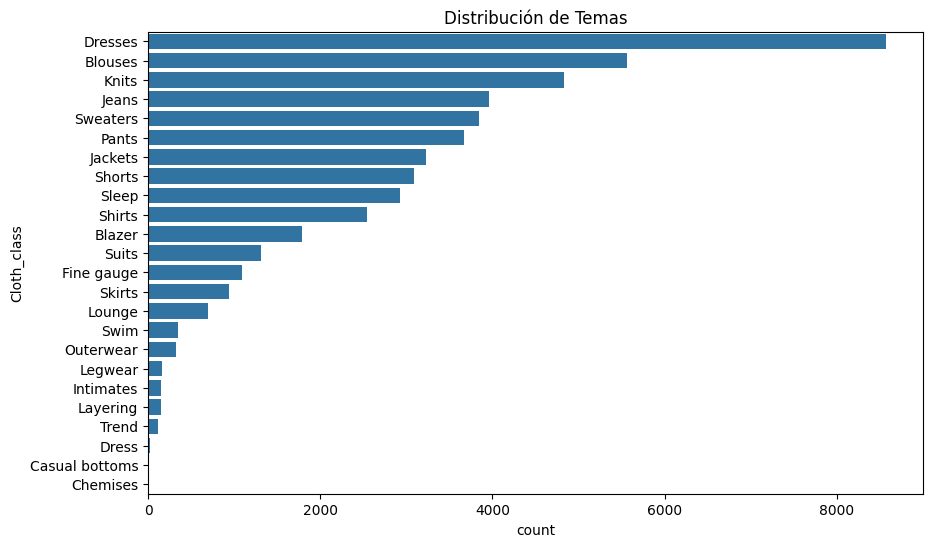

In [ ]:
# Distribución de temas
plt.figure(figsize=(10, 6))
sns.countplot(y='Cloth_class', data=df, order=df['Cloth_class'].value_counts().index)
plt.title("Distribución de Temas")
plt.show()

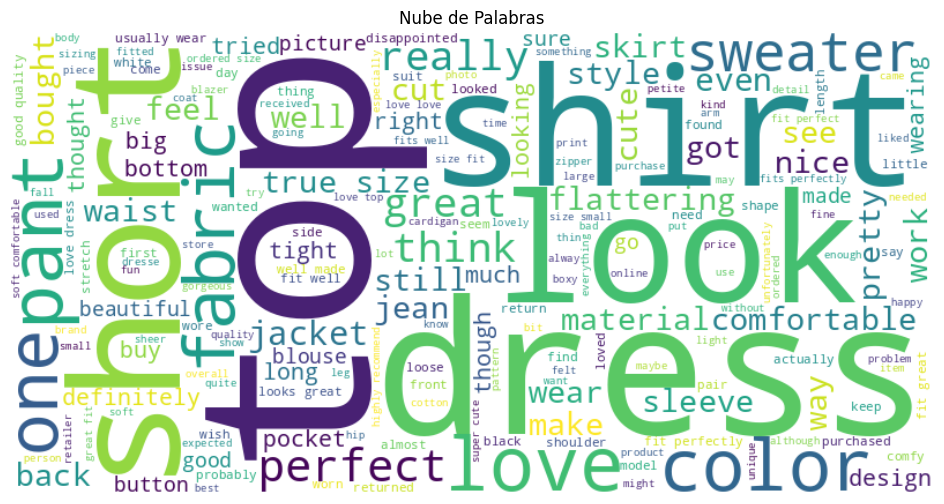

In [ ]:
from wordcloud import WordCloud


# Unir todos los textos limpios en un solo string
text = " ".join(df['clean_text'].dropna().tolist())

# Crear la nube de palabras
wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='viridis').generate(text)

# Mostrar la imagen
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Nube de Palabras")
plt.show()


#TextBlob

<ipython-input-55-2010484281>:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='SentimentLabel', data=df, order=['Positivo', 'Neutro', 'Negativo'], palette={'Positivo': 'green', 'Neutro': 'blue', 'Negativo': 'red'})


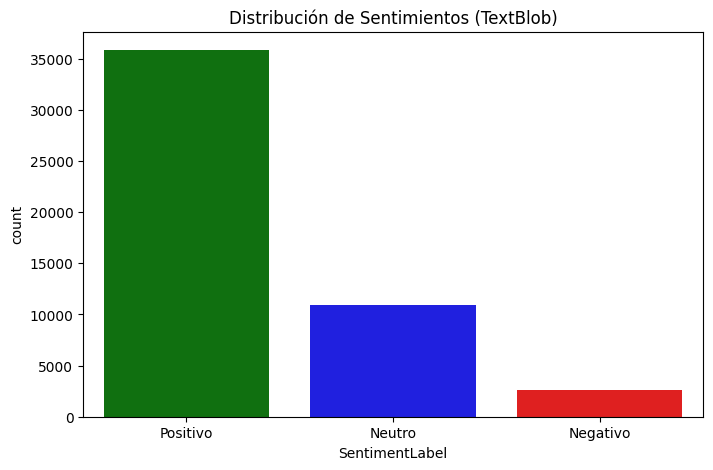

In [ ]:
# Función para obtener polaridad
def get_sentiment(text):
    if not text:
        return 0.0
    analysis = TextBlob(text)
    return analysis.sentiment.polarity

# Aplicar polaridad
df['SentimentPolarity'] = df['clean_text'].apply(get_sentiment)

# Clasificar sentimientos
def classify_sentiment(polarity):
    if polarity > 0.1:
        return "Positivo"
    elif polarity < -0.1:
        return "Negativo"
    else:
        return "Neutro"

df['SentimentLabel'] = df['SentimentPolarity'].apply(classify_sentiment)

# Visualización
plt.figure(figsize=(8, 5))
sns.countplot(x='SentimentLabel', data=df, order=['Positivo', 'Neutro', 'Negativo'], palette={'Positivo': 'green', 'Neutro': 'blue', 'Negativo': 'red'})
plt.title("Distribución de Sentimientos (TextBlob)")
plt.show()


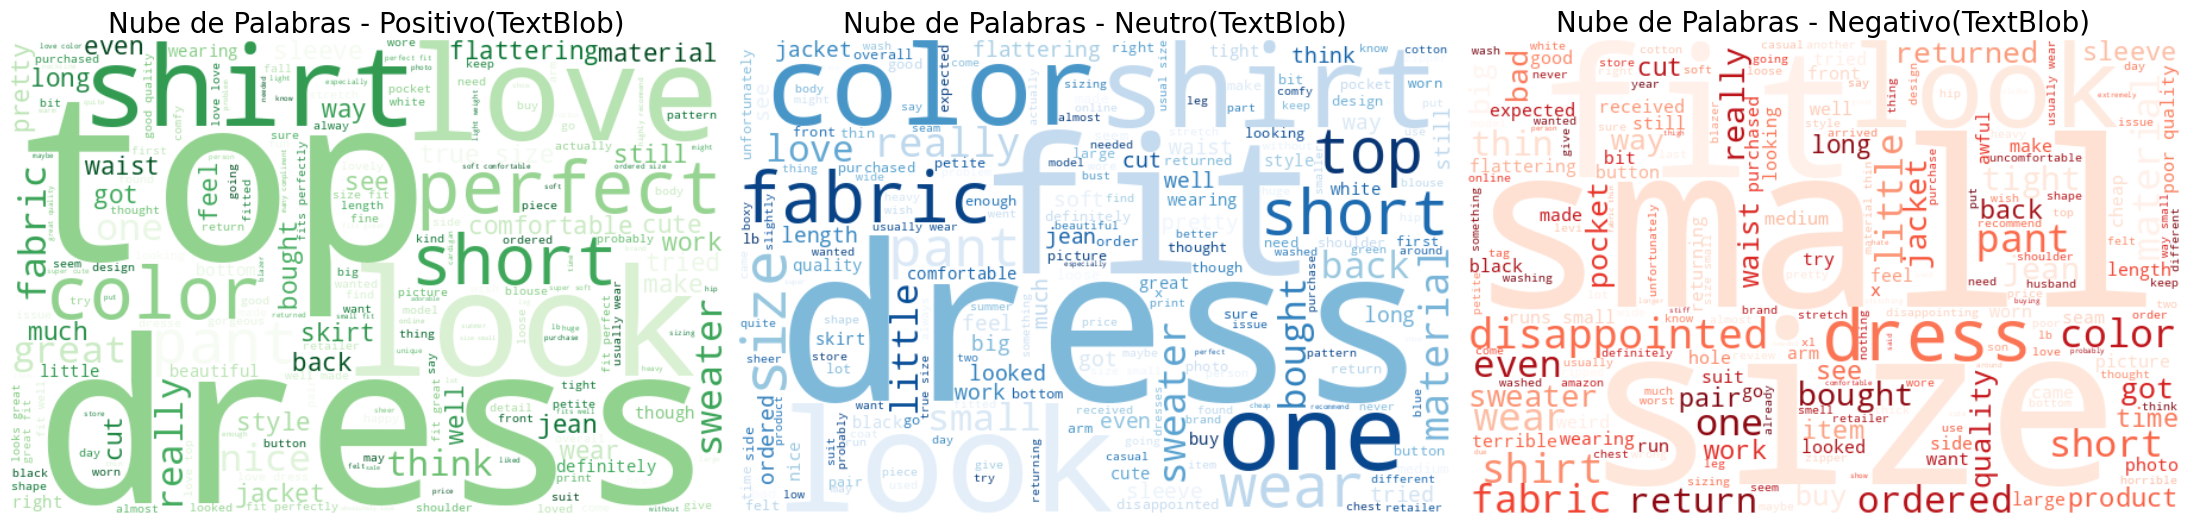

In [ ]:
# Configuración general para la visualización
fig, axes = plt.subplots(1, 3, figsize=(22, 8))
sentiments = ['Positivo', 'Neutro', 'Negativo']
colors = ['Greens', 'Blues', 'Reds']

for i, sentiment in enumerate(sentiments):
    # Concatenar todos los textos con ese sentimiento
    text = " ".join(df[df['SentimentLabel'] == sentiment]['clean_text'].dropna())

    # Generar la nube
    wordcloud = WordCloud(width=600, height=400, background_color='white', colormap=colors[i]).generate(text)

    # Visualizar en su respectivo subplot
    axes[i].imshow(wordcloud, interpolation='bilinear')
    axes[i].axis('off')
    axes[i].set_title(f'Nube de Palabras - {sentiment}(TextBlob)', fontsize=20)

plt.tight_layout()
plt.show()


#VADER

<ipython-input-56-3119882561>:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='VaderLabel', data=df, order=['Positivo', 'Neutro', 'Negativo'],palette={'Positivo': 'green', 'Neutro': 'blue', 'Negativo': 'red'})


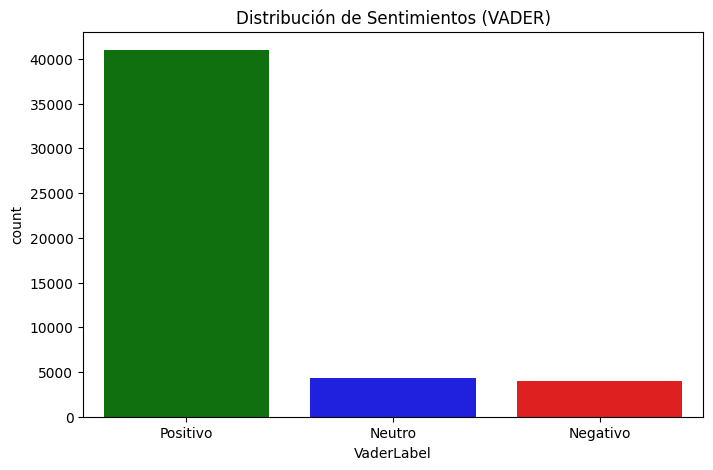

In [ ]:
sia = SentimentIntensityAnalyzer()

def get_vader_sentiment(text):
    if not text:
        return 0.0
    return sia.polarity_scores(text)['compound']

df['VaderSentiment'] = df['clean_text'].apply(get_vader_sentiment)

# Clasificar sentimientos
df['VaderLabel'] = df['VaderSentiment'].apply(lambda x: 'Positivo' if x > 0.05 else ('Negativo' if x < -0.05 else 'Neutro'))

# Visualización
plt.figure(figsize=(8, 5))
sns.countplot(x='VaderLabel', data=df, order=['Positivo', 'Neutro', 'Negativo'],palette={'Positivo': 'green', 'Neutro': 'blue', 'Negativo': 'red'})
plt.title("Distribución de Sentimientos (VADER)")
plt.show()


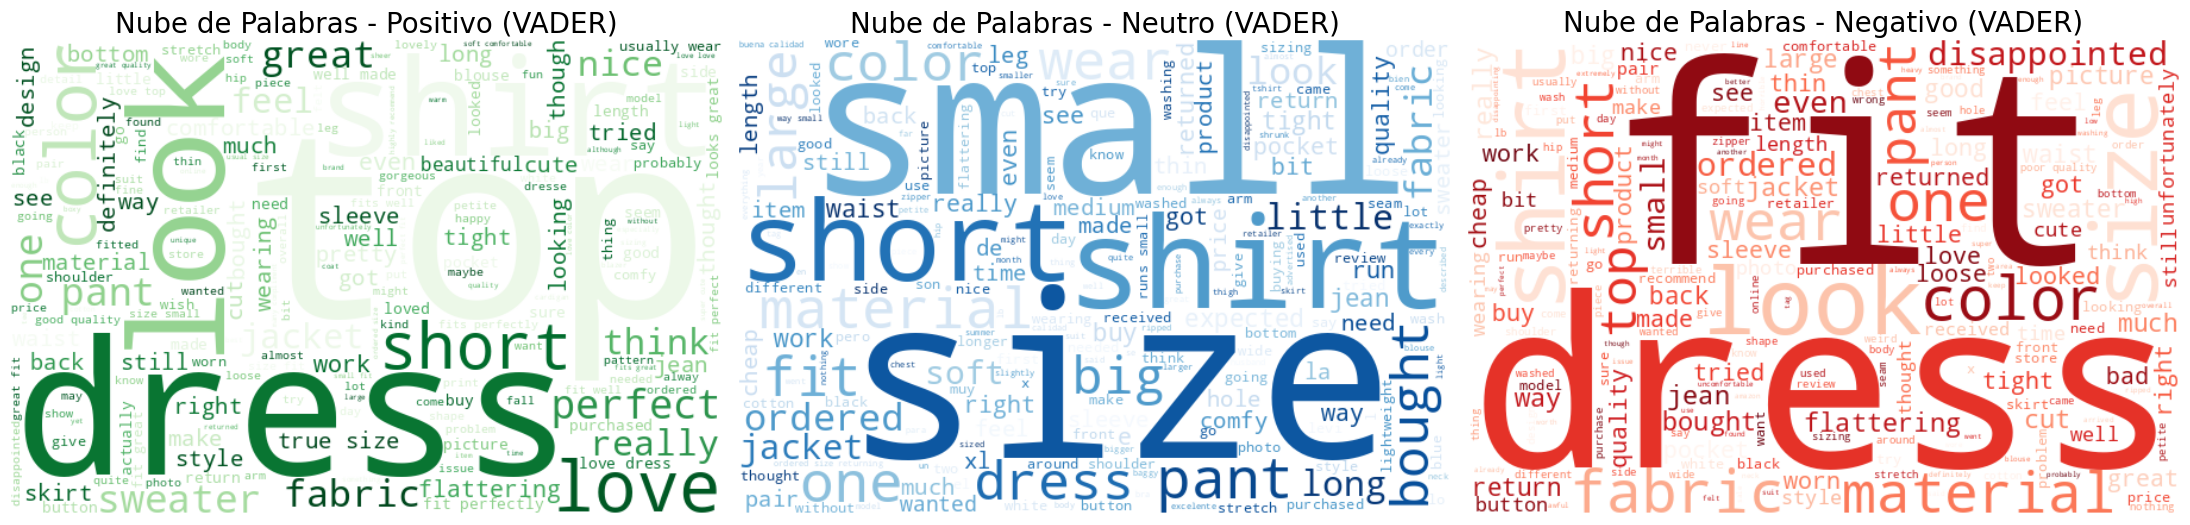

In [ ]:
# Configuración para visualización
fig, axes = plt.subplots(1, 3, figsize=(22, 8))
sentiments = ['Positivo', 'Neutro', 'Negativo']
colors = ['Greens', 'Blues', 'Reds']

for i, sentiment in enumerate(sentiments):
    # Texto unido por sentimiento (usando VADER)
    text = " ".join(df[df['VaderLabel'] == sentiment]['clean_text'].dropna())

    # Crear la nube de palabras
    wordcloud = WordCloud(width=600, height=400, background_color='white', colormap=colors[i]).generate(text)

    # Mostrar
    axes[i].imshow(wordcloud, interpolation='bilinear')
    axes[i].axis('off')
    axes[i].set_title(f'Nube de Palabras - {sentiment} (VADER)', fontsize=20)

plt.tight_layout()
plt.show()


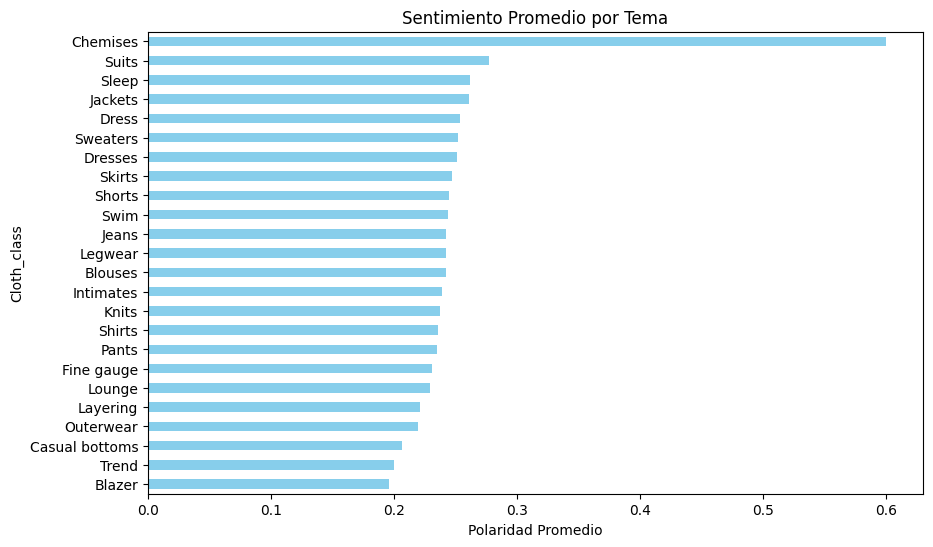

In [ ]:
#Estadísticas por tema
sentiment_by_topic = df.groupby('Cloth_class')['SentimentPolarity'].mean().sort_values()
plt.figure(figsize=(10, 6))
sentiment_by_topic.plot(kind='barh', color='skyblue')
plt.title("Sentimiento Promedio por Tema")
plt.xlabel("Polaridad Promedio")
plt.show()

#Comparativa TexBlob y VADER

In [ ]:
def rating_to_label(rating):
    if rating >= 4.0:
        return "Positivo"
    elif rating <= 2.0:
        return "Negativo"
    else:
        return "Neutro"

df['TrueLabel'] = df['Cons_rating'].apply(rating_to_label)


In [ ]:
print("Métricas TextBlob:")
print(classification_report(df['TrueLabel'], df['SentimentLabel']))

print("Métricas VADER:")
print(classification_report(df['TrueLabel'], df['VaderLabel']))



Métricas TextBlob:
              precision    recall  f1-score   support

    Negativo       0.62      0.22      0.33      7148
      Neutro       0.18      0.35      0.24      5564
    Positivo       0.84      0.82      0.83     36626

    accuracy                           0.68     49338
   macro avg       0.54      0.46      0.46     49338
weighted avg       0.73      0.68      0.69     49338

Métricas VADER:
              precision    recall  f1-score   support

    Negativo       0.57      0.32      0.41      7148
      Neutro       0.15      0.12      0.13      5564
    Positivo       0.81      0.91      0.86     36626

    accuracy                           0.73     49338
   macro avg       0.51      0.45      0.47     49338
weighted avg       0.70      0.73      0.71     49338



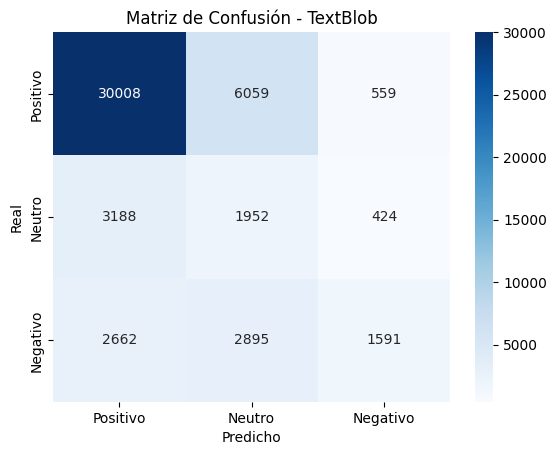

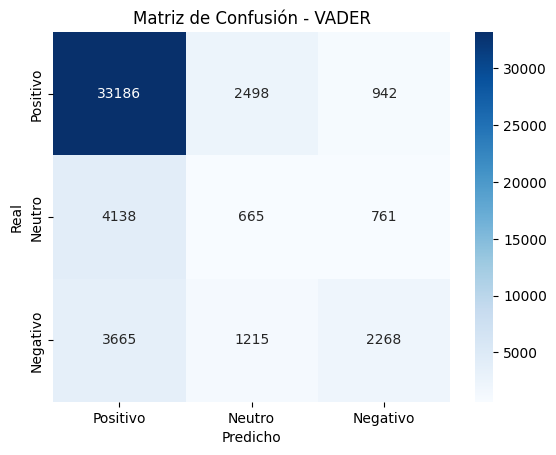

In [ ]:
from sklearn.metrics import confusion_matrix

def plot_confusion(y_true, y_pred, title):
    labels = ['Positivo', 'Neutro', 'Negativo']
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=labels, yticklabels=labels)
    plt.xlabel("Predicho")
    plt.ylabel("Real")
    plt.title(title)
    plt.show()

plot_confusion(df['TrueLabel'], df['SentimentLabel'], "Matriz de Confusión - TextBlob")
plot_confusion(df['TrueLabel'], df['VaderLabel'], "Matriz de Confusión - VADER")


#BERT

In [ ]:
!pip install transformers torch pandas numpy matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 95.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 69.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 40.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 83.3 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling nvidia-nvjitlink-cu12-12.5.82:
      Successfully uninstalled nvidia-nvjitlin

In [ ]:
from transformers import pipeline, AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
import torch

In [ ]:
#Cargar el modelo y tokenizador
model_name = "nlptown/bert-base-multilingual-uncased-sentiment"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

#Crear una pipeline de análisis de sentimientos
sentiment_analyzer = pipeline("sentiment-analysis", model=model, tokenizer=tokenizer)

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/953 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/872k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/669M [00:00<?, ?B/s]

Device set to use cpu


In [ ]:
def get_bert_sentiment(text):
    try:
        result = sentiment_analyzer(text)[0]  # HuggingFace ya maneja truncado automático
        label = result['label']
        if label in ['1 star', '2 stars']:
            return "Negativo"
        elif label == '3 stars':
            return "Neutro"
        else:
            return "Positivo"
    except:
        return "Neutro"


In [ ]:
#Aplicar BERT a las interacciones (puede tardar varios minutos)
df['BERTSentiment'] = df['clean_text'].apply(get_bert_sentiment)

#Ver resultados
print(df[['Review', 'BERTSentiment']].head(10))

                                              Review BERTSentiment
0  Absolutely wonderful - silky and sexy and comf...      Positivo
1  Love this dress!  it's sooo pretty.  i happene...      Negativo
2  I had such high hopes for this dress and reall...        Neutro
3  I love, love, love this jumpsuit. it's fun, fl...      Positivo
4  This shirt is very flattering to all due to th...      Positivo
5  I love tracy reese dresses, but this one is no...      Negativo
6  I aded this in my basket at hte last mintue to...      Negativo
7  I ordered this in carbon for store pick up, an...      Positivo
8  I love this dress. i usually get an xs but it ...        Neutro
9  I'm 5"5' and 125 lbs. i ordered the s petite t...        Neutro


<ipython-input-57-2410706394>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='BERTSentiment', data=df, order=["Positivo", "Neutro", "Negativo"], palette={'Positivo': 'green', 'Neutro': 'blue', 'Negativo': 'red'})


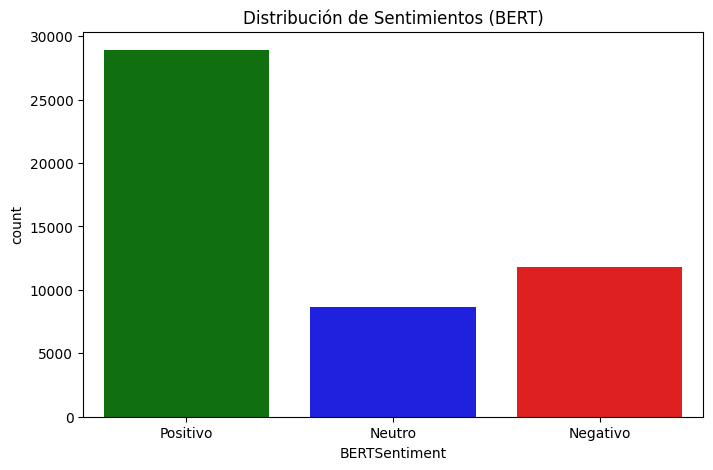

In [ ]:
#Distribución de sentimientos
plt.figure(figsize=(8, 5))
sns.countplot(x='BERTSentiment', data=df, order=["Positivo", "Neutro", "Negativo"], palette={'Positivo': 'green', 'Neutro': 'blue', 'Negativo': 'red'})
plt.title("Distribución de Sentimientos (BERT)")
plt.show()

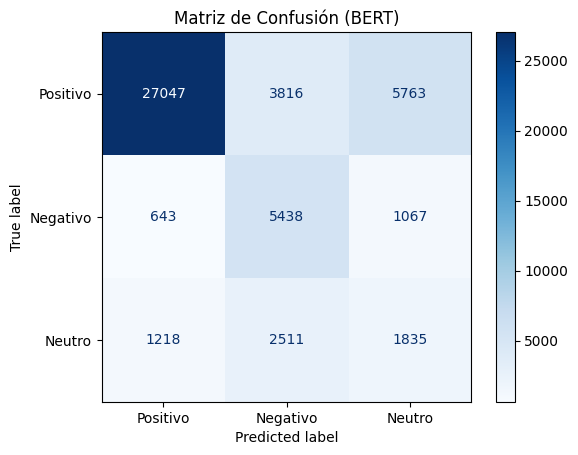

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

# Mapeo de sentimientos a valores numéricos
sentiment_mapping = {'Negativo': 0, 'Neutro': 1, 'Positivo': 2}

# Mapear los valores numéricos para BERT y las etiquetas reales
df['BERTSentimentNumeric'] = df['BERTSentiment'].map(sentiment_mapping)
df['TrueSentimentNumeric'] = df['TrueLabel'].map(sentiment_mapping)

# Generar la matriz de confusión
cm_bert = confusion_matrix(df['TrueSentimentNumeric'], df['BERTSentimentNumeric'])

# Reordenar la matriz de confusión para que el orden sea Positivo, Negativo, Neutro
cm_bert_reordered = cm_bert[[2, 0, 1], :]  # Reordenamos las filas
cm_bert_reordered = cm_bert_reordered[:, [2, 0, 1]]  # Reordenamos las columnas

# Visualizar la matriz de confusión para BERT con el orden Positivo, Negativo, Neutro
disp_bert = ConfusionMatrixDisplay(confusion_matrix=cm_bert_reordered, display_labels=['Positivo', 'Negativo', 'Neutro'])
disp_bert.plot(cmap='Blues', values_format='d')
plt.title("Matriz de Confusión (BERT)")
plt.show()


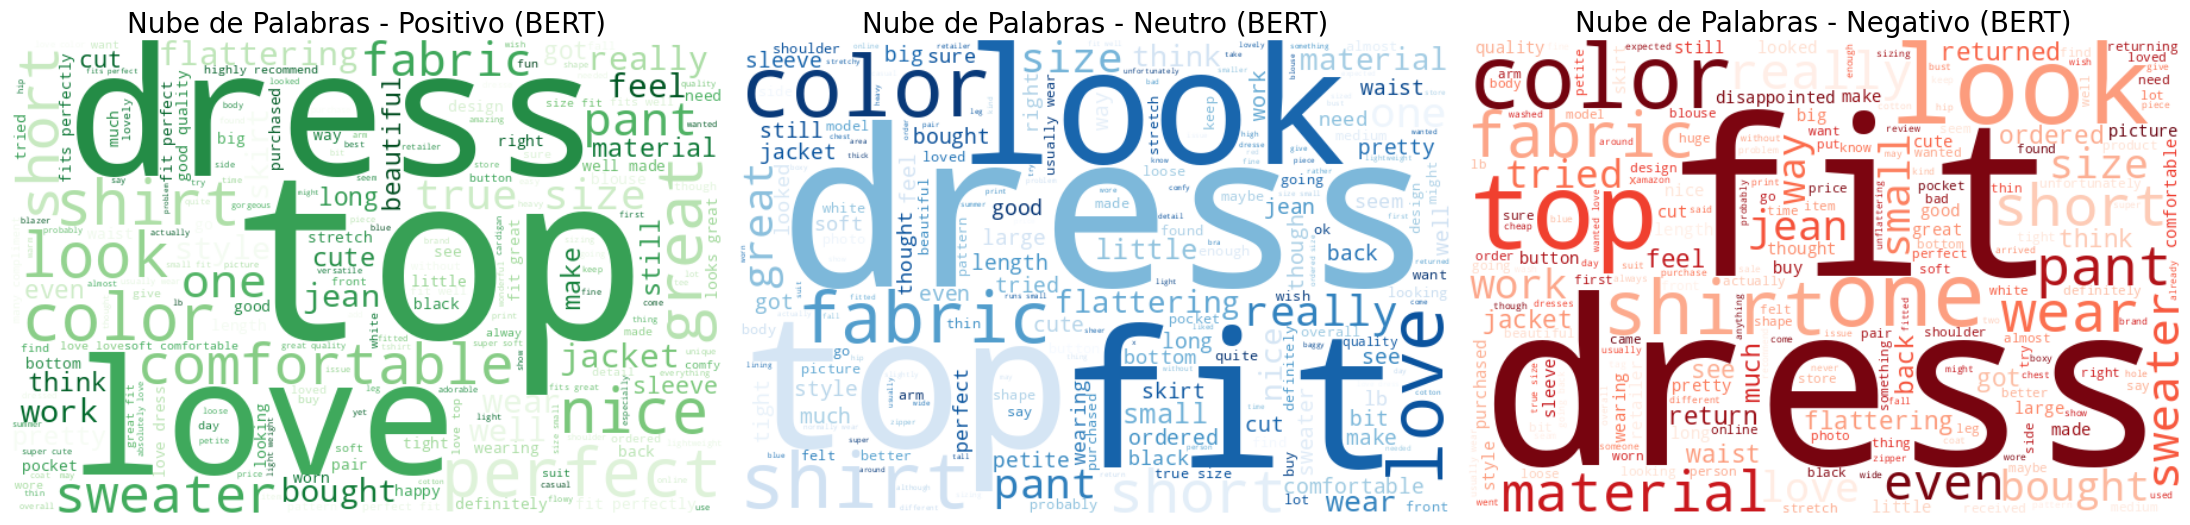

In [ ]:
# Configuración general para la visualización
fig, axes = plt.subplots(1, 3, figsize=(22, 8))
sentiments = ['Positivo', 'Neutro', 'Negativo']
colors = ['Greens', 'Blues', 'Reds']

for i, sentiment in enumerate(sentiments):
    # Concatenar todos los textos con ese sentimiento
    text = " ".join(df[df['BERTSentiment'] == sentiment]['clean_text'].dropna())

    # Generar la nube de palabras
    wordcloud = WordCloud(width=600, height=400, background_color='white', colormap=colors[i]).generate(text)

    # Visualizar en su respectivo subplot
    axes[i].imshow(wordcloud, interpolation='bilinear')
    axes[i].axis('off')
    axes[i].set_title(f'Nube de Palabras - {sentiment} (BERT)', fontsize=20)

plt.tight_layout()
plt.show()


In [ ]:
print("Métricas BERT:")
print(classification_report(df['TrueLabel'], df['BERTSentiment']))

Métricas BERT:
              precision    recall  f1-score   support

    Negativo       0.46      0.76      0.58      7148
      Neutro       0.21      0.33      0.26      5564
    Positivo       0.94      0.74      0.83     36626

    accuracy                           0.70     49338
   macro avg       0.54      0.61      0.55     49338
weighted avg       0.79      0.70      0.73     49338



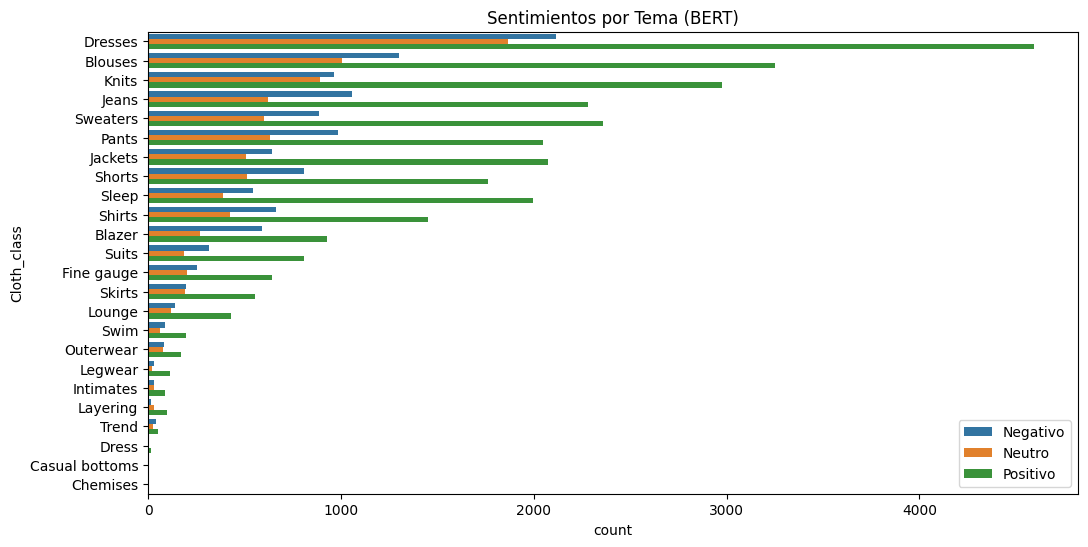

In [ ]:
#Sentimiento por tema
plt.figure(figsize=(12, 6))
sns.countplot(y='Cloth_class', hue='BERTSentiment', data=df,
              order=df['Cloth_class'].value_counts().index,
              hue_order=["Negativo", "Neutro", "Positivo"])
plt.title("Sentimientos por Tema (BERT)")
plt.legend(loc='lower right')
plt.show()

#RoBERTa

In [ ]:
!pip install transformers
!pip install torch
!pip install nltk
!pip install scipy



In [ ]:
from scipy.special import softmax

# Cargar modelo y tokenizador
model_name = "cardiffnlp/twitter-roberta-base-sentiment"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)


config.json:   0%|          | 0.00/747 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/499M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

In [ ]:
def get_roberta_sentiment_v3(text):
    try:
        text = text.strip()

        encoded_input = tokenizer(text, return_tensors='pt', truncation=True, max_length=512)
        output = model(**encoded_input)

        scores = output[0][0].detach().numpy()
        scores = softmax(scores)

        labels = ['NEGATIVE', 'NEUTRAL', 'POSITIVE']
        ranking = scores.argsort()[::-1]

        return labels[ranking[0]]
    except:
        return "NEUTRAL"


In [ ]:
# Aplicarlo sobre clean_text
df['RoBERTaSentiment'] = df['clean_text'].apply(get_roberta_sentiment_v3)

# Mostrar algunos ejemplos
df[['Review', 'RoBERTaSentiment']].head()


,Review,RoBERTaSentiment
0,Absolutely wonderful - silky and sexy and comf...,POSITIVE
1,Love this dress! it's sooo pretty. i happene...,POSITIVE
2,I had such high hopes for this dress and reall...,POSITIVE
3,"I love, love, love this jumpsuit. it's fun, fl...",POSITIVE
4,This shirt is very flattering to all due to th...,POSITIVE


In [ ]:
print("Valores únicos en TrueLabel:")
print(df['TrueLabel'].unique())

print("\nValores únicos en RoBERTaSentiment:")
print(df['RoBERTaSentiment'].unique())


Valores únicos en TrueLabel:
['Positivo' 'Neutro' 'Negativo']

Valores únicos en RoBERTaSentiment:
['Positivo' 'Negativo' 'Neutro']


In [ ]:
# Traducir RoBERTaSentiment a español para que coincida con TrueLabel
traduccion = {'NEGATIVE': 'Negativo', 'NEUTRAL': 'Neutro', 'POSITIVE': 'Positivo'}
df['RoBERTaSentiment'] = df['RoBERTaSentiment'].map(traduccion)


In [ ]:
# Mapeo unificado en español
sentiment_mapping = {'Negativo': 0, 'Neutro': 1, 'Positivo': 2}

df['RoBERTaSentimentNumeric'] = df['RoBERTaSentiment'].map(sentiment_mapping)
df['TrueSentimentNumeric'] = df['TrueLabel'].map(sentiment_mapping)


In [ ]:
# Asegurarse de tener etiquetas en español
traduccion = {'NEGATIVE': 'Negativo', 'NEUTRAL': 'Neutro', 'POSITIVE': 'Positivo'}
df['RoBERTaSentimentTraducido'] = df['RoBERTaSentiment'].map(traduccion)

<ipython-input-58-1118110258>:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='RoBERTaSentiment', data=df, order=['Positivo', 'Neutro', 'Negativo'], palette={'Positivo': 'green', 'Neutro': 'blue', 'Negativo': 'red'})


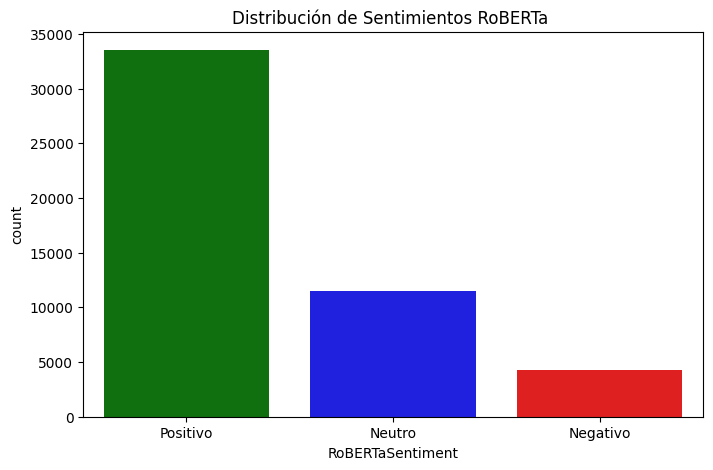

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(x='RoBERTaSentiment', data=df, order=['Positivo', 'Neutro', 'Negativo'], palette={'Positivo': 'green', 'Neutro': 'blue', 'Negativo': 'red'})
plt.title("Distribución de Sentimientos RoBERTa ")
plt.show()


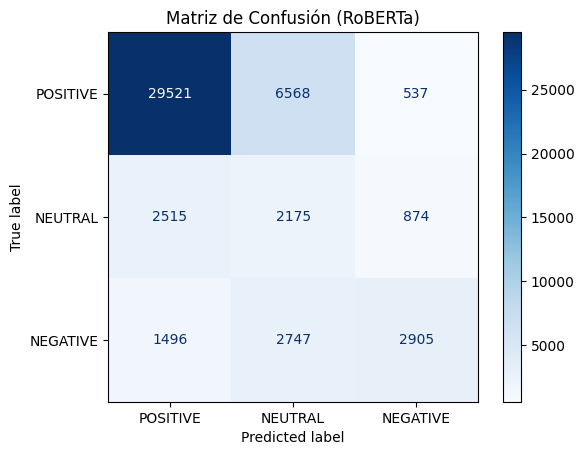

In [ ]:
# Mapeo de sentimientos a valores numéricos (según RoBERTa)
sentiment_mapping = {'Positivo': 2,'Negativo': 0, 'Neutro': 1}

# Mapear a numérico
df['RoBERTaSentimentNumeric'] = df['RoBERTaSentiment'].map(sentiment_mapping)
df['TrueSentimentNumeric'] = df['TrueLabel'].map(sentiment_mapping)

# Eliminar filas con NaN (errores de mapeo)
df_roberta_clean = df.dropna(subset=['RoBERTaSentimentNumeric', 'TrueSentimentNumeric'])
df_roberta_clean[['RoBERTaSentimentNumeric', 'TrueSentimentNumeric']] = df_roberta_clean[['RoBERTaSentimentNumeric', 'TrueSentimentNumeric']].astype(int)

# Generar matriz de confusión con labels fijos (aunque falten clases en los datos)
cm_roberta = confusion_matrix(
    df_roberta_clean['TrueSentimentNumeric'],
    df_roberta_clean['RoBERTaSentimentNumeric'],
    labels=[0, 1, 2]  # NEGATIVE, NEUTRAL, POSITIVE
)

# Reordenar: POSITIVE (2), NEUTRAL (1), NEGATIVE (0)
orden = [2, 1, 0]
cm_roberta_reordered = cm_roberta[orden, :][:, orden]

# Mostrar la matriz con etiquetas en el orden deseado
disp_roberta = ConfusionMatrixDisplay(
    confusion_matrix=cm_roberta_reordered,
    display_labels=['POSITIVE', 'NEUTRAL', 'NEGATIVE']
)
disp_roberta.plot(cmap='Blues', values_format='d')
plt.title("Matriz de Confusión (RoBERTa)")
plt.show()


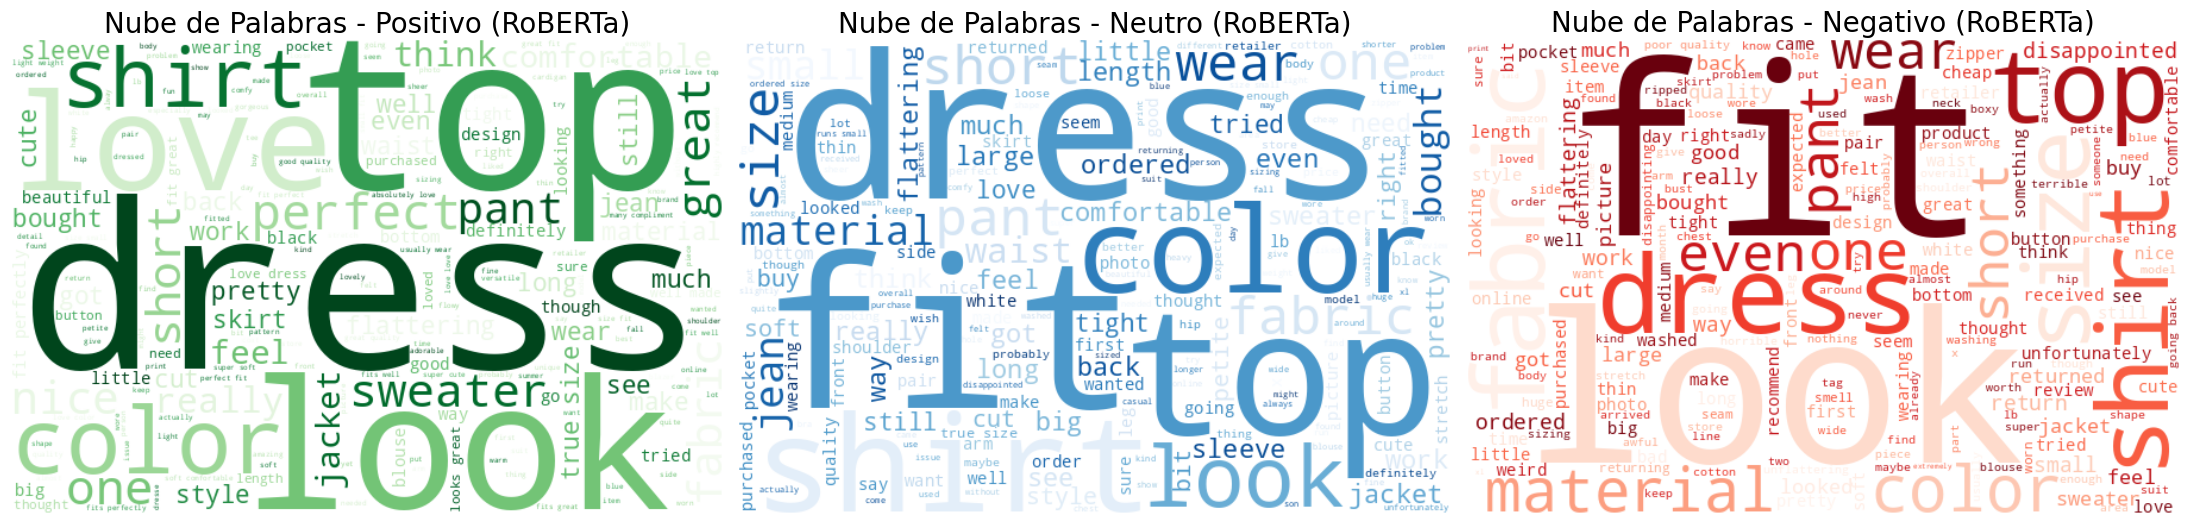

In [ ]:
# Configuración general para la visualización
fig, axes = plt.subplots(1, 3, figsize=(22, 8))
# Use the Spanish labels that are actually in the 'RoBERTaSentiment' column
sentiments = ['Positivo', 'Neutro', 'Negativo']
colors = ['Greens', 'Blues', 'Reds']

for i, sentiment in enumerate(sentiments):
    # Concatenar todos los textos con ese sentimiento según RoBERTa
    # Filter using the Spanish sentiment labels
    text = " ".join(df[df['RoBERTaSentiment'] == sentiment]['clean_text'].dropna())

    # Generar la nube de palabras

    wordcloud = WordCloud(width=600, height=400, background_color='white', colormap=colors[i]).generate(text)

    # Visualizar en su respectivo subplot
    axes[i].imshow(wordcloud, interpolation='bilinear')
    axes[i].axis('off')
    # Update the title to reflect the Spanish labels being used for filtering
    axes[i].set_title(f'Nube de Palabras - {sentiment} (RoBERTa)', fontsize=20)

plt.tight_layout()
plt.show()

In [ ]:
print("Métricas RoBERTa:")
print(classification_report(df['TrueLabel'], df['RoBERTaSentiment']))

Métricas RoBERTa:
              precision    recall  f1-score   support

    Negativo       0.67      0.41      0.51      7148
      Neutro       0.19      0.39      0.26      5564
    Positivo       0.88      0.81      0.84     36626

    accuracy                           0.70     49338
   macro avg       0.58      0.53      0.53     49338
weighted avg       0.77      0.70      0.73     49338



#Comparativa Modelos

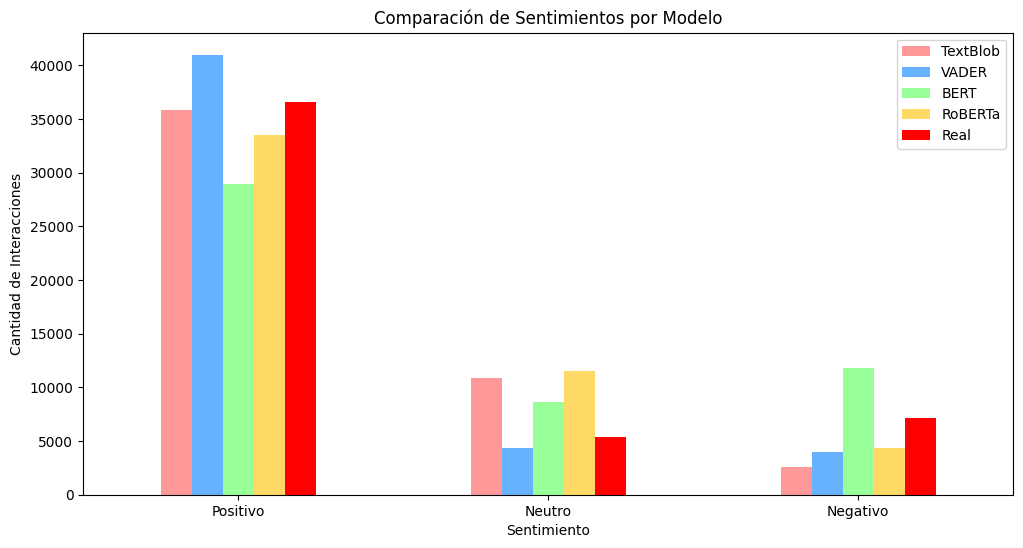

In [ ]:
# Contar sentimientos por modelo y asegurarse del orden correcto
sentiment_order = ['Positivo', 'Neutro', 'Negativo']

counts = pd.DataFrame({
    'TextBlob': df['SentimentLabel'].value_counts().reindex(sentiment_order).fillna(0), # Use fillna() instead of fillvalue
    'VADER': df['VaderLabel'].value_counts().reindex(sentiment_order).fillna(0), # Use fillna() instead of fillvalue
    'BERT': df['BERTSentiment'].value_counts().reindex(sentiment_order).fillna(0), # Use fillna() instead of fillvalue
    'RoBERTa': df['RoBERTaSentiment'].value_counts().reindex(sentiment_order).fillna(0), # Use fillna() instead of fillvalue
    'Real': df['Sentimiento'].value_counts().reindex(sentiment_order).fillna(0)
})

# Graficar
counts.plot(kind='bar', figsize=(12, 6), color=['#FF9999', '#66B2FF', '#99FF99', '#FFD966','red'])
plt.title("Comparación de Sentimientos por Modelo")
plt.xlabel("Sentimiento")
plt.ylabel("Cantidad de Interacciones")
plt.xticks(rotation=0)
plt.show()